In [1]:
import torch
from torch import nn
import pandas as pd
from torch import optim
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from torch.utils.data import Dataset, DataLoader
import numpy as np
import re
import pymorphy3
from nltk.corpus import stopwords
import nltk

In [2]:
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
np.random.seed(seed)

In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'

In [4]:
device

'cuda'

In [5]:
df = pd.read_csv(r'../../data/Petitions.csv')

In [6]:
df.head()

,id,public_petition_text,reason_category
0,3168490,снег на дороге,Благоустройство
1,3219678,очистить кабельный киоск от рекламы,Благоустройство
2,2963920,"Просим убрать все деревья и кустарники, которы...",Благоустройство
3,3374910,Неудовлетворительное состояние парадной - надп...,Содержание МКД
4,3336285,Граффити,Благоустройство


In [7]:
nltk.download('stopwords')
morph = pymorphy3.MorphAnalyzer()   
russian_stopwords = set(stopwords.words('russian'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Denis\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [8]:
class PetitionsDataset(Dataset):
    def __init__(self, path, column, window_size=5):
        self.df = pd.read_csv(path)
        self.df[column] = self.df[column].map(lambda x: re.sub(r'[^а-яё\s]', '', x, flags=re.IGNORECASE))
        self.df[column] = self.df[column].map(lambda x: x.lower())
        self.df[column] = self.df[column].map(lambda x: re.sub(r'\s+', ' ', x).strip())
        self.df[column] = self.df[column].map(lambda x: '\n'.join([line.strip() for line in x.split('\n')]))
        self.df[column] = self.df[column].map(lambda x: ' '.join(morph.parse(word)[0].normal_form for word in x.split()))
        self.df[column] = self.df[column].map(lambda x: ' '.join([word for word in x.split() if word not in russian_stopwords]))
        
        
        self.column = column

        self.text = '<|sep|>'.join(list(self.df[column]))
        self.sentences = self.text.split('<|sep|>')
        self.windows = []
        for sent in self.sentences:
            self.windows.extend(PetitionsDataset.get_window_items(sent, window_size)) 
        
        words = ' '.join(self.sentences).split()
        self.vocab = sorted(list(set(words)))
        self.vocab_size = len(self.vocab)
        self.word_indexes = {word: i for (i, word) in enumerate(self.vocab)}
        

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        X = torch.tensor(PetitionsDataset.sentence_to_one_hot(self.word_indexes, self.windows[idx][0]))
        y = torch.tensor(PetitionsDataset.word_to_one_hot_vec(self.word_indexes, self.windows[idx][1]))
        return X, y

    @staticmethod
    def get_window_items(text, window_size):
        result = []
        text = text.split()
        for i in range(len(text) - window_size + 1):
            for j in range(i, i + window_size):
                result.append(
                    ((text[i:j] + text[j+1:i+window_size]), text[j])
                )
        return result
        
    @staticmethod
    def word_to_one_hot_vec(word_indexes, word):
        vector = np.zeros(len(word_indexes), dtype='float32')
        vector[word_indexes[word]] = 1
        return vector

    @staticmethod
    def sentence_to_one_hot(word_indexes, sentence):
        a = []
        for word in sentence:
            a.append(PetitionsDataset.word_to_one_hot_vec(word_indexes, word))
        return np.array(a)

In [9]:
class PetitionsDatasetSkipGram(Dataset):
    def __init__(self, path, column, window_size=5):
        self.df = pd.read_csv(path)
        self.df[column] = self.df[column].map(lambda x: re.sub(r'[^а-яё\s]', '', x, flags=re.IGNORECASE))
        self.df[column] = self.df[column].map(lambda x: x.lower())
        self.df[column] = self.df[column].map(lambda x: re.sub(r'\s+', ' ', x).strip())
        self.df[column] = self.df[column].map(lambda x: '\n'.join([line.strip() for line in x.split('\n')]))
        self.df[column] = self.df[column].map(lambda x: ' '.join(morph.parse(word)[0].normal_form for word in x.split()))
        self.df[column] = self.df[column].map(lambda x: ' '.join([word for word in x.split() if word not in russian_stopwords]))
        
        
        self.column = column

        self.text = '<|sep|>'.join(list(self.df[column]))
        self.sentences = self.text.split('<|sep|>')
        self.windows = []
        for sent in self.sentences:
            wdw = PetitionsDatasetSkipGram.get_window_items(sent, window_size) # -> ([[мама, мыть], рама])
            for w in wdw:
                for context_word in w[0]:
                    self.windows.append(([[w[1]], context_word])) 
        
        words = ' '.join(self.sentences).split()
        self.vocab = sorted(list(set(words)))
        self.vocab_size = len(self.vocab)
        self.word_indexes = {word: i for (i, word) in enumerate(self.vocab)}
        

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        X = torch.tensor(PetitionsDatasetSkipGram.sentence_to_one_hot(self.word_indexes, self.windows[idx][0]))
        y = torch.tensor(PetitionsDatasetSkipGram.word_to_one_hot_vec(self.word_indexes, self.windows[idx][1]))
        return X, y

    @staticmethod
    def get_window_items(text, window_size):
        result = []
        text = text.split()
        for i in range(len(text) - window_size + 1):
            for j in range(i, i + window_size):
                result.append(
                    ((text[i:j] + text[j+1:i+window_size]), text[j])
                )
        return result
        
    @staticmethod
    def word_to_one_hot_vec(word_indexes, word):
        vector = np.zeros(len(word_indexes), dtype='float32')
        vector[word_indexes[word]] = 1
        return vector

    @staticmethod
    def sentence_to_one_hot(word_indexes, sentence):
        a = []
        for word in sentence:
            a.append(PetitionsDatasetSkipGram.word_to_one_hot_vec(word_indexes, word))
        return np.array(a)

In [10]:
class ProjectionLayer(nn.Module):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.linear = nn.Linear(vocab_size, d_model)

    def forward(self, x):
        x = self.linear(x)
        out = x.mean(dim=1)
        return out

In [11]:
class OutputLayer(nn.Module):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.linear = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        logits = self.linear(x)
        return logits

In [12]:
class CBoW(nn.Module):
    def __init__(self, vocab_size, d_model=256):
        super().__init__()
        self.proj_layer = ProjectionLayer(vocab_size, d_model)
        self.out_layer = OutputLayer(vocab_size, d_model)

    def forward(self, x):
        x = self.proj_layer(x)
        logits = self.out_layer(x)
        return logits

In [13]:
batch_size = 256
window_size = 5
d_model = 256
epochs = 3

In [14]:
ds = PetitionsDataset(r'../../data/Petitions.csv', 'public_petition_text', window_size)

In [15]:
ds.windows

[(['убрать', 'всё', 'дерево', 'кустарник'], 'просить'),
 (['просить', 'всё', 'дерево', 'кустарник'], 'убрать'),
 (['просить', 'убрать', 'дерево', 'кустарник'], 'всё'),
 (['просить', 'убрать', 'всё', 'кустарник'], 'дерево'),
 (['просить', 'убрать', 'всё', 'дерево'], 'кустарник'),
 (['всё', 'дерево', 'кустарник', 'который'], 'убрать'),
 (['убрать', 'дерево', 'кустарник', 'который'], 'всё'),
 (['убрать', 'всё', 'кустарник', 'который'], 'дерево'),
 (['убрать', 'всё', 'дерево', 'который'], 'кустарник'),
 (['убрать', 'всё', 'дерево', 'кустарник'], 'который'),
 (['дерево', 'кустарник', 'который', 'выйти'], 'всё'),
 (['всё', 'кустарник', 'который', 'выйти'], 'дерево'),
 (['всё', 'дерево', 'который', 'выйти'], 'кустарник'),
 (['всё', 'дерево', 'кустарник', 'выйти'], 'который'),
 (['всё', 'дерево', 'кустарник', 'который'], 'выйти'),
 (['кустарник', 'который', 'выйти', 'предел'], 'дерево'),
 (['дерево', 'который', 'выйти', 'предел'], 'кустарник'),
 (['дерево', 'кустарник', 'выйти', 'предел'], 'ко

In [16]:
ds_skipgram = PetitionsDatasetSkipGram(r'../../data/Petitions.csv', 'public_petition_text', window_size)

In [17]:
ds_skipgram.windows

[[['просить'], 'убрать'],
 [['просить'], 'всё'],
 [['просить'], 'дерево'],
 [['просить'], 'кустарник'],
 [['убрать'], 'просить'],
 [['убрать'], 'всё'],
 [['убрать'], 'дерево'],
 [['убрать'], 'кустарник'],
 [['всё'], 'просить'],
 [['всё'], 'убрать'],
 [['всё'], 'дерево'],
 [['всё'], 'кустарник'],
 [['дерево'], 'просить'],
 [['дерево'], 'убрать'],
 [['дерево'], 'всё'],
 [['дерево'], 'кустарник'],
 [['кустарник'], 'просить'],
 [['кустарник'], 'убрать'],
 [['кустарник'], 'всё'],
 [['кустарник'], 'дерево'],
 [['убрать'], 'всё'],
 [['убрать'], 'дерево'],
 [['убрать'], 'кустарник'],
 [['убрать'], 'который'],
 [['всё'], 'убрать'],
 [['всё'], 'дерево'],
 [['всё'], 'кустарник'],
 [['всё'], 'который'],
 [['дерево'], 'убрать'],
 [['дерево'], 'всё'],
 [['дерево'], 'кустарник'],
 [['дерево'], 'который'],
 [['кустарник'], 'убрать'],
 [['кустарник'], 'всё'],
 [['кустарник'], 'дерево'],
 [['кустарник'], 'который'],
 [['который'], 'убрать'],
 [['который'], 'всё'],
 [['который'], 'дерево'],
 [['который']

In [18]:
ds[0][1]

tensor([0., 0., 0.,  ..., 0., 0., 0.])

In [19]:
dataloader = DataLoader(ds, batch_size)

In [20]:
dataloader_skipgram = DataLoader(ds_skipgram, batch_size)

In [21]:
model = CBoW(ds.vocab_size, d_model).to(device)
optimizer = optim.Adam(params=model.parameters())
loss_fn = nn.CrossEntropyLoss()

In [22]:
def train_loop(dataloader, model, optimizer, loss_fn, train_losses):
    model.train()
    size = len(dataloader.dataset)
    batch_losses = []
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        
        pred = model(X)
        loss = loss_fn(pred, y)
        batch_losses.append(loss.item())
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch_size * batch + len(X)
            print(f'loss: {loss:>7f} [{current:>5d}/{size:>5d}]')
        
    train_losses.append(sum(batch_losses) / len(batch_losses))

In [23]:
def test_loop(dataloader, model, loss_fn, test_losses):
    model.eval()
    num_batch = len(dataloader)
    f1, recall, precision, accuracy = 0, 0, 0, 0
    test_loss = 0
    all_pred = []
    all_targets = []
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()

            all_pred.extend(pred.cpu().argmax(1).numpy())
            all_targets.extend(y.cpu().numpy())

    test_loss /= num_batch

    average_type = 'weighted'
    f1 = f1_score(all_targets, all_pred, average=average_type, zero_division=0)
    recall = recall_score(all_targets, all_pred, average=average_type, zero_division=0)
    precision = precision_score(all_targets, all_pred, average=average_type, zero_division=0)
    accuracy = accuracy_score(all_targets, all_pred)

    test_losses.append(test_loss)
    
    print(f'Avg loss: {test_loss:>8.2f} | f1: {f1:>5.2f} | precision: {precision:>5.2f} | recall: {recall:>5.2f} | accuracy: {accuracy:>5.2f}')

In [24]:
train_losses = []

In [25]:
for i in range(epochs):
    print(f'Epoch {i+1}')
    train_loop(dataloader, model, optimizer, loss_fn, train_losses)
    print('-' * 30)

Epoch 1
loss: 9.939268 [  256/1869020]
loss: 7.632696 [25856/1869020]
loss: 7.356454 [51456/1869020]
loss: 7.386919 [77056/1869020]
loss: 7.703196 [102656/1869020]
loss: 7.434265 [128256/1869020]
loss: 8.187572 [153856/1869020]
loss: 6.918952 [179456/1869020]
loss: 8.137497 [205056/1869020]
loss: 8.230444 [230656/1869020]
loss: 7.673067 [256256/1869020]
loss: 7.244224 [281856/1869020]
loss: 6.976629 [307456/1869020]
loss: 7.297912 [333056/1869020]
loss: 7.260480 [358656/1869020]
loss: 7.832238 [384256/1869020]
loss: 7.475504 [409856/1869020]
loss: 8.111764 [435456/1869020]
loss: 8.033640 [461056/1869020]
loss: 6.407167 [486656/1869020]
loss: 5.747314 [512256/1869020]
loss: 8.097057 [537856/1869020]
loss: 6.401273 [563456/1869020]
loss: 6.830109 [589056/1869020]
loss: 7.682763 [614656/1869020]
loss: 7.292629 [640256/1869020]
loss: 6.787027 [665856/1869020]
loss: 7.839537 [691456/1869020]
loss: 6.540321 [717056/1869020]
loss: 6.504713 [742656/1869020]
loss: 7.072734 [768256/1869020]
loss

In [26]:
import matplotlib.pyplot as plt

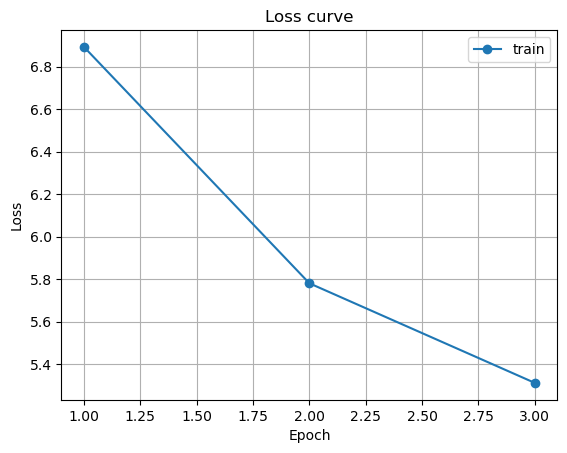

In [27]:
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', label='train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curve')
plt.legend()
plt.grid(True)

# SkipGram

In [28]:
model_skipgram = CBoW(ds_skipgram.vocab_size, d_model).to(device)
optimizer_2 = optim.Adam(params=model_skipgram.parameters())
loss_fn_2 = nn.CrossEntropyLoss()

In [29]:
train_losses_2 = []

In [30]:
for i in range(epochs):
    print(f'Epoch {i+1}')
    train_loop(dataloader_skipgram, model_skipgram, optimizer_2, loss_fn_2, train_losses_2)
    print('-' * 30)

Epoch 1
loss: 9.941341 [  256/7476080]
loss: 7.295811 [25856/7476080]
loss: 7.784503 [51456/7476080]
loss: 6.299139 [77056/7476080]
loss: 4704.973633 [102656/7476080]
loss: 7.640315 [128256/7476080]
loss: 6.994603 [153856/7476080]
loss: 7729.113770 [179456/7476080]
loss: 7.306270 [205056/7476080]
loss: 7.251662 [230656/7476080]
loss: 8.738639 [256256/7476080]
loss: 10.333773 [281856/7476080]
loss: 7.171835 [307456/7476080]
loss: 9.231892 [333056/7476080]
loss: 9.954339 [358656/7476080]
loss: 18819.832031 [384256/7476080]
loss: 7.195408 [409856/7476080]
loss: 7.875354 [435456/7476080]
loss: 8.515350 [461056/7476080]
loss: 8.061764 [486656/7476080]
loss: 16769.542969 [512256/7476080]
loss: 9.131702 [537856/7476080]
loss: 833.218506 [563456/7476080]
loss: 7.355676 [589056/7476080]
loss: 8.687506 [614656/7476080]
loss: 29720.375000 [640256/7476080]
loss: 7.603182 [665856/7476080]
loss: 7.711396 [691456/7476080]
loss: 6.948108 [717056/7476080]
loss: 16.211704 [742656/7476080]
loss: 8.345454

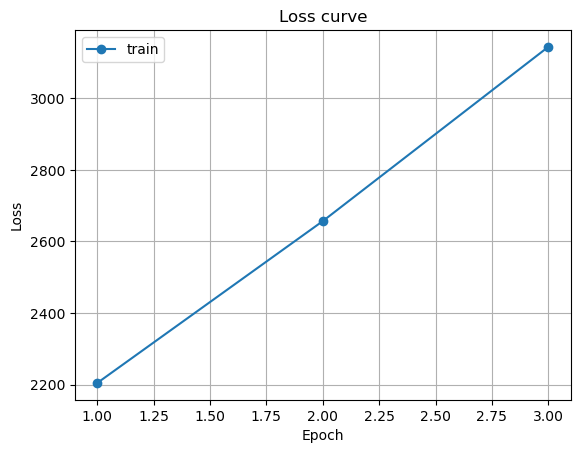

In [31]:
plt.plot(range(1, len(train_losses_2) + 1), train_losses_2, marker='o', label='train')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss curve')
plt.legend()
plt.grid(True)

In [32]:
import pickle

In [33]:
with open(r'../../models/cbow.pkl', 'wb') as f:
    pickle.dump(model, f)

In [34]:
with open(r'../../models/skipgram.pkl', 'wb') as f:
    pickle.dump(model_skipgram, f)

In [35]:
embedder = model.proj_layer.linear

In [36]:
embedder_skipgram = model_skipgram.proj_layer.linear

In [37]:
def cosine_similarity(emb1, emb2):
    cosine_similarity = torch.dot(emb1, emb2) / (torch.norm(emb1) * torch.norm(emb2))
    return cosine_similarity

def cosine_dist(cosine_similarity):
    return 1 - cosine_similarity

def embedding_word(word: str):
    one_hot = PetitionsDataset.word_to_one_hot_vec(ds.word_indexes, word)
    embedding = embedder(torch.tensor(one_hot).to(device))
    return embedding

def embedding_word_skipgram(word: str):
    one_hot = PetitionsDatasetSkipGram.word_to_one_hot_vec(ds_skipgram.word_indexes, word)
    embedding = embedder_skipgram(torch.tensor(one_hot).to(device))
    return embedding

def angular_distance(cosine_similarity):
    sim_clamped = torch.clamp(cosine_similarity, -1.0, 1.0)
    return torch.arccos(sim_clamped) / torch.pi

def compare_word(word_1: str, word_2: str):
    emb_1 = embedding_word(word_1)
    emb_2 = embedding_word(word_2)

    cos_sim = cosine_similarity(emb_1, emb_2)
    cos_dist = angular_distance(cos_sim)
    return cos_dist.item()

In [38]:
words = list(ds_skipgram.word_indexes.keys())

In [39]:
words2 = list(ds_skipgram.word_indexes.keys())

In [40]:
vectors = np.array([np.array(embedding_word(word).detach().cpu()) for word in words])

In [41]:
vectors2 = np.array([np.array(embedding_word_skipgram(word).detach().cpu()) for word in words2])

In [42]:
np.savetxt(r'../../data/vectors.tsv', vectors, delimiter='\t')

In [43]:
np.savetxt(r'../../data/vectors2.tsv', vectors2, delimiter='\t')

In [44]:
with open(r'../../data/metadata.tsv', 'w', encoding='utf-8') as f:
    for w in words:
        f.write(w + "\n")

In [45]:
import tensorflow as tf
from tensorboard.plugins import projector

In [46]:
vectors1 = np.loadtxt(r'../../data/logs/vectors.tsv', delimiter='\t')
vectors2 = np.loadtxt(r'../../data/logs/vectors2.tsv', delimiter='\t')

embedding_var1 = tf.Variable(vectors1, name='word_embeddings1')
embedding_var2 = tf.Variable(vectors2, name='word_embeddings2')

checkpoint = tf.train.Checkpoint(
    word_embeddings1=embedding_var1,
    word_embeddings2=embedding_var2
)
checkpoint.save(r'../../data/logs/embedding.ckpt')  


config = projector.ProjectorConfig()

emb1 = config.embeddings.add()
emb1.tensor_name = "word_embeddings1/.ATTRIBUTES/VARIABLE_VALUE"  
emb1.metadata_path = 'metadata.tsv' 

emb2 = config.embeddings.add()
emb2.tensor_name = "word_embeddings2/.ATTRIBUTES/VARIABLE_VALUE"
emb2.metadata_path = 'metadata.tsv'

projector.visualize_embeddings(r'../../data/logs', config)